In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../DATA/WineQT.csv')

In [3]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [5]:
df = df.drop('Id', axis=1)

In [6]:
df['quality'].value_counts()

quality
5    483
6    462
7    143
4     33
8     16
3      6
Name: count, dtype: int64

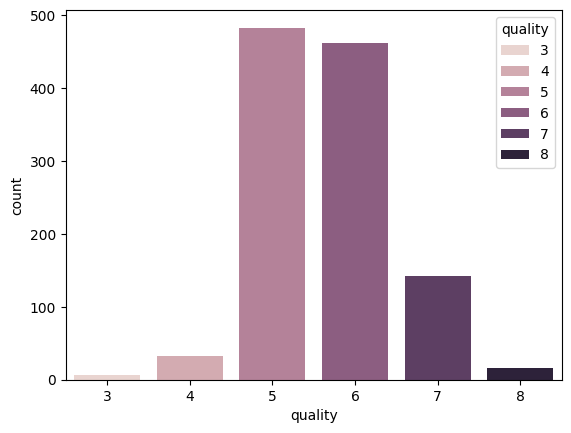

In [7]:
sns.countplot(data=df, x='quality', hue='quality');

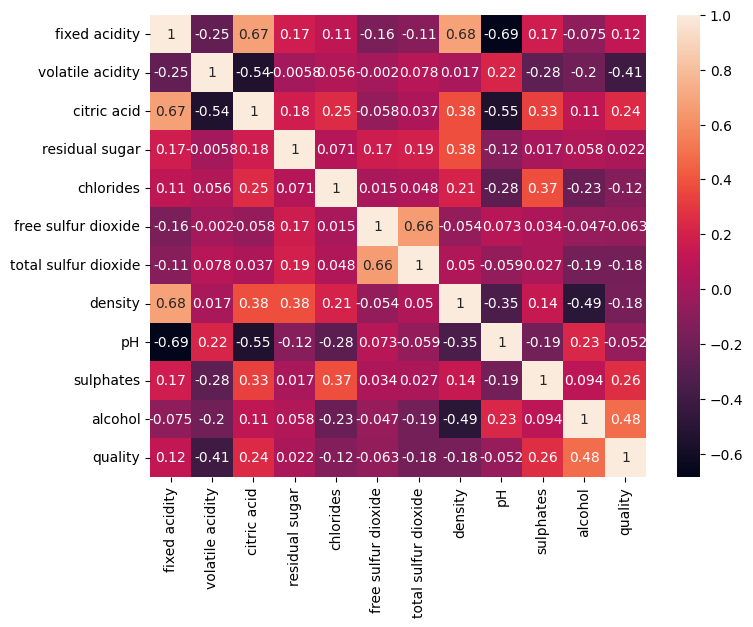

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True);

In [9]:
df['quality'] = df['quality'].map(lambda x: 1 if x>=6 else 0)

In [10]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.impute import KNNImputer
from sklearn.ensemble import IsolationForest

In [11]:
X = df.drop('quality', axis=1)

In [12]:
y = df['quality']

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [14]:
iso_forest = IsolationForest(contamination=0.01, random_state=104, n_jobs=-1, n_estimators=100)

In [15]:
mask = iso_forest.fit_predict(X_train)

In [16]:
X_train_cleaned = X_train[mask==1]
y_train_cleaned = y_train[mask==1]

In [17]:
X_train.shape

(914, 11)

In [18]:
X_train_cleaned.shape

(904, 11)

In [19]:
num_features = X_train.columns.tolist()

In [20]:
num_features

['fixed acidity',
 'volatile acidity',
 'citric acid',
 'residual sugar',
 'chlorides',
 'free sulfur dioxide',
 'total sulfur dioxide',
 'density',
 'pH',
 'sulphates',
 'alcohol']

In [21]:
num_transformer = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])

In [22]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features)
    ],
    remainder='passthrough'
)

In [23]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier(n_jobs=-1))
])

In [58]:
param_grid = {
    'model__n_neighbors': range(1, 55, 2),
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan'],
    'model__p': [1, 1.5, 2, 3]
}

In [59]:
grid_pipe = GridSearchCV(estimator=pipe,
                         param_grid=param_grid,
                         scoring='roc_auc',
                         n_jobs=-1,
                         cv=10
)

In [60]:
%%time
grid_pipe.fit(X_train_cleaned, y_train_cleaned)

CPU times: total: 4.33 s
Wall time: 13.9 s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...(n_jobs=-1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__metric': ['euclidean', 'manhattan'], 'model__n_neighbors': range(1, 55, 2), 'model__p': [1, 1.5, ...], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computa

In [61]:
y_pred = grid_pipe.predict(X_test)
y_pred_proba = grid_pipe.predict_proba(X_test)[:, 1]
y_train_proba = grid_pipe.predict_proba(X_train)[:, 1]

In [62]:
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)

roc_auc_test = roc_auc_score(y_test, y_pred_proba)
roc_auc_train = roc_auc_score(y_train, y_train_proba)

In [63]:
best_knn = grid_pipe.best_estimator_.named_steps['model']
print(f"  Количество соседей (n_neighbors): {best_knn.n_neighbors}")
print(f"  Функция весов (weights):          {best_knn.weights}")
print(f"  Формула расстояния (metric):      {best_knn.metric}")
print(f"  Алгоритм поиска (algorithm):      {best_knn.algorithm}")
print(f"                            P:      {best_knn.p}")

  Количество соседей (n_neighbors): 47
  Функция весов (weights):          distance
  Формула расстояния (metric):      euclidean
  Алгоритм поиска (algorithm):      auto
                            P:      1


In [64]:
accuracy

0.777292576419214

In [65]:
recall

0.8629032258064516

In [66]:
precision

0.7588652482269503

In [67]:
roc_auc_test

0.8652073732718893

In [68]:
roc_auc_train

0.9999517488624794

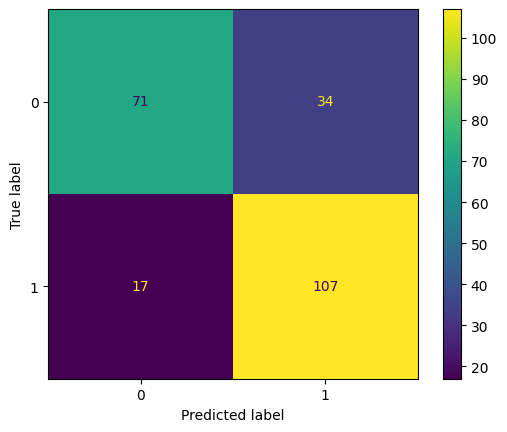

In [69]:
ConfusionMatrixDisplay.from_estimator(grid_pipe, X_test, y_test);

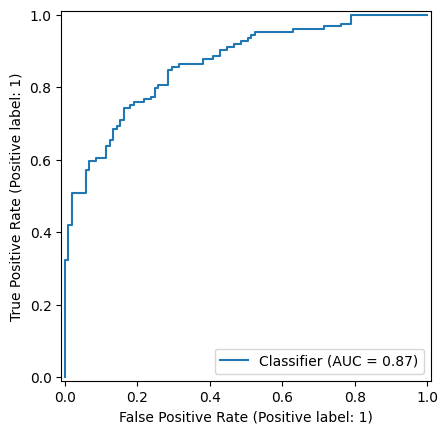

In [70]:
RocCurveDisplay.from_predictions(y_test, y_pred_proba);

In [71]:
mask = iso_forest.fit_predict(X)

In [72]:
X_cleaned = X[mask==1]
y_cleaned = y[mask==1]

In [73]:
X.shape

(1143, 11)

In [74]:
X_cleaned.shape

(1131, 11)

In [75]:
grid_pipe.fit(X_cleaned, y_cleaned)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...(n_jobs=-1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__metric': ['euclidean', 'manhattan'], 'model__n_neighbors': range(1, 55, 2), 'model__p': [1, 1.5, ...], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computa

In [76]:
y_full_proba = grid_pipe.predict_proba(X_cleaned)[:, 1]

In [77]:
best_final_knn = grid_pipe.best_estimator_.named_steps['model']
print(f"  Количество соседей (n_neighbors): {best_final_knn.n_neighbors}")
print(f"  Функция весов (weights):          {best_final_knn.weights}")
print(f"  Формула расстояния (metric):      {best_final_knn.metric}")
print(f"  Алгоритм поиска (algorithm):      {best_final_knn.algorithm}")
print(f"                            P:      {best_final_knn.p}")

  Количество соседей (n_neighbors): 51
  Функция весов (weights):          distance
  Формула расстояния (metric):      euclidean
  Алгоритм поиска (algorithm):      auto
                            P:      1


In [78]:
roc_auc_full = roc_auc_score(y_cleaned, y_full_proba)

In [79]:
roc_auc_full

1.0

In [80]:
wine_custom_profiles = {
    'fixed acidity': [7.4, 8.5],           
    'volatile acidity': [0.70, 0.28],       
    'citric acid': [0.00, 0.45],            
    'residual sugar': [1.9, 2.6],           
    'chlorides': [0.076, 0.042],            
    'free sulfur dioxide': [11.0, 15.0],    
    'total sulfur dioxide': [34.0, 40.0],   
    'density': [0.9978, 0.9952],            
    'pH': [3.51, 3.25],                     
    'sulphates': [0.56, 0.85],              
    'alcohol': [9.4, 12.8]                  
}

In [81]:
custom_wine_df = pd.DataFrame(wine_custom_profiles)

In [82]:
custom_wine_df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,8.5,0.28,0.45,2.6,0.042,15.0,40.0,0.9952,3.25,0.85,12.8


In [83]:
custom_preds = grid_pipe.best_estimator_.predict(custom_wine_df)
custom_probs = grid_pipe.best_estimator_.predict_proba(custom_wine_df)[:, 1] 

In [84]:
wine_classes = {
    0: "❌ БЮДЖЕТНОЕ / ОБЫЧНОЕ ВИНО (Качество 3-5)",
    1: "🍇 ПРЕМИАЛЬНОЕ / ВЫСОКОЕ КАЧЕСТВО (Качество 6-8) 🍷✨"
}

print("="*80)
print("ВЕРДИКТ МОДЕЛИ ПО ВИНУ:")
print("="*80)

for idx in range(2):
    predicted_class = custom_preds[idx]
    
    if predicted_class == 1:
        confidence = custom_probs[idx] * 100
    else:
        confidence = (1 - custom_probs[idx]) * 100
        
    print(f"Бутылка №{idx+1} ({'Ожидалось Бюджетное' if idx==0 else 'Ожидалось Премиум'}):")
    print(f"  -> Вердикт модели: {wine_classes[predicted_class]}")
    print(f"  -> Уверенность модели: {confidence:.2f}%")
    print("-" * 80)

ВЕРДИКТ МОДЕЛИ ПО ВИНУ:
Бутылка №1 (Ожидалось Бюджетное):
  -> Вердикт модели: ❌ БЮДЖЕТНОЕ / ОБЫЧНОЕ ВИНО (Качество 3-5)
  -> Уверенность модели: 100.00%
--------------------------------------------------------------------------------
Бутылка №2 (Ожидалось Премиум):
  -> Вердикт модели: 🍇 ПРЕМИАЛЬНОЕ / ВЫСОКОЕ КАЧЕСТВО (Качество 6-8) 🍷✨
  -> Уверенность модели: 94.73%
--------------------------------------------------------------------------------


In [85]:
class_percents = df['quality'].value_counts(normalize=True) * 100

baseline_string = f"0: {class_percents[0]:.1f}%, 1: {class_percents[1]:.1f}%"
print(f"{baseline_string}")

0: 45.7%, 1: 54.3%


In [86]:
import json
import os

advanced_report = {
    "project": "Wine Quality Prediction",
    "model": "KNeighborsClassifier",
    "trained_date": '2026-07',
    "test_parameters": {
        "cv": grid_pipe.cv,
        "n_neighbors": best_knn.n_neighbors,
        "weights": best_knn.weights,
        "metric": best_knn.metric,
        "p": best_knn.p
    },
    "final_parameters": {
        "cv": grid_pipe.cv,
        "n_neighbors": best_final_knn.n_neighbors,
        "weights": best_final_knn.weights,
        "metric": best_final_knn.metric,
        "p": best_final_knn.p
    },
    "metrics": {
        "Accuracy Score": accuracy,
        "Precision Score": precision,
        "Recall": recall,
        "ROC AUC Score Train": roc_auc_train,
        "ROC AUC Score Test": roc_auc_test,
        "ROC AUC Score Full": roc_auc_full,
        "Class Balance": baseline_string
    }
}


filename = "model_description.json"

with open(filename, "w", encoding="utf-8") as f:
    json.dump(advanced_report, f, indent=4, ensure_ascii=False)

In [87]:
from joblib import dump, load

In [88]:
dump(grid_pipe, "model/wine_quality_predict_k_neighbors_classifier_2026_v1.pkl")

['model/wine_quality_predict_k_neighbors_classifier_2026_v1.pkl']

In [89]:
loaded_pipe = load('model/wine_quality_predict_k_neighbors_classifier_2026_v1.pkl')

In [90]:
custom_preds = loaded_pipe.best_estimator_.predict(custom_wine_df)
custom_probs = loaded_pipe.best_estimator_.predict_proba(custom_wine_df)[:, 1] 

In [91]:
wine_classes = {
    0: "❌ БЮДЖЕТНОЕ / ОБЫЧНОЕ ВИНО (Качество 3-5)",
    1: "🍇 ПРЕМИАЛЬНОЕ / ВЫСОКОЕ КАЧЕСТВО (Качество 6-8) 🍷✨"
}

print("="*80)
print("ВЕРДИКТ МОДЕЛИ ПО ВИНУ:")
print("="*80)

for idx in range(2):
    predicted_class = custom_preds[idx]
    
    if predicted_class == 1:
        confidence = custom_probs[idx] * 100
    else:
        confidence = (1 - custom_probs[idx]) * 100
        
    print(f"Бутылка №{idx+1} ({'Ожидалось Бюджетное' if idx==0 else 'Ожидалось Премиум'}):")
    print(f"  -> Вердикт модели: {wine_classes[predicted_class]}")
    print(f"  -> Уверенность модели: {confidence:.2f}%")
    print("-" * 80)

ВЕРДИКТ МОДЕЛИ ПО ВИНУ:
Бутылка №1 (Ожидалось Бюджетное):
  -> Вердикт модели: ❌ БЮДЖЕТНОЕ / ОБЫЧНОЕ ВИНО (Качество 3-5)
  -> Уверенность модели: 100.00%
--------------------------------------------------------------------------------
Бутылка №2 (Ожидалось Премиум):
  -> Вердикт модели: 🍇 ПРЕМИАЛЬНОЕ / ВЫСОКОЕ КАЧЕСТВО (Качество 6-8) 🍷✨
  -> Уверенность модели: 94.73%
--------------------------------------------------------------------------------
